In [ ]:
# ============================================================
# 1. INSTALL LIBRARY & DOWNLOAD DATASET DARI ROBOFLOW
# ============================================================

!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="8I8Mxn53KVFFQFH1OZxw")
project = rf.workspace("ganeshhsy").project("tuberculosis-pccam")
version = project.version(3)
dataset = version.download("folder")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 88.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 110.8 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Tuberculosis-3 in folder:: 100%|██████████| 6981/6981 [00:00<00:00, 10642.47it/s]


In [ ]:
# ============================================================
# 2. PERHITUNGAN JUMLAH DATASET
# ============================================================

import os
from collections import Counter

base = "/content/Tuberculosis-3"
splits = ["train", "valid", "test"]

counts = Counter()
for split in splits:
    for cls in os.listdir(os.path.join(base, split)):
        path = os.path.join(base, split, cls)
        counts[cls] += len([
            f for f in os.listdir(path)
            if f.lower().endswith(('.jpg', '.png', '.jpeg'))
        ])

print(counts)
print("Total:", sum(counts.values()))


Counter({'Normal': 3500, 'tuberculosis data': 3470})
Total: 6970


In [ ]:
# ============================================================
# 3. PERSIAPAN DATASET
# ============================================================

import tensorflow as tf
from tensorflow.data import AUTOTUNE

IMG_SIZE = (224, 224)
DATA_ROOT = "/content/Tuberculosis-3"
SEED = 42

rescale = tf.keras.layers.Rescaling(1./255)

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.05),
    tf.keras.layers.RandomContrast(0.1)
])

def prepare_train(x, y):
    x = rescale(x)
    x = augment(x, training=True)
    return x, y

def prepare_eval(x, y):
    x = rescale(x)
    return x, y


Found 4879 files belonging to 2 classes.
Found 1045 files belonging to 2 classes.
class_names: ['Normal', 'tuberculosis data']


In [ ]:
# ============================================================
# 4. MEMBANGUN DATASET TRAIN, VALIDASI, DAN TEST
# ============================================================

def build_datasets(batch_size):
    train = tf.keras.utils.image_dataset_from_directory(
        os.path.join(DATA_ROOT, "train"),
        image_size=IMG_SIZE,
        batch_size=batch_size,
        label_mode="categorical",
        seed=SEED
    )

    val = tf.keras.utils.image_dataset_from_directory(
        os.path.join(DATA_ROOT, "valid"),
        image_size=IMG_SIZE,
        batch_size=batch_size,
        label_mode="categorical",
        shuffle=False
    )

    test = tf.keras.utils.image_dataset_from_directory(
        os.path.join(DATA_ROOT, "test"),
        image_size=IMG_SIZE,
        batch_size=batch_size,
        label_mode="categorical",
        shuffle=False
    )

    class_names = train.class_names
    num_classes = len(class_names)

    train = train.map(prepare_train).prefetch(AUTOTUNE)
    val = val.map(prepare_eval).cache().prefetch(AUTOTUNE)
    test = test.map(prepare_eval).cache().prefetch(AUTOTUNE)

    return train, val, test, class_names, num_classes

train_ds, val_ds, test_ds, class_names, num_classes = build_datasets(32)
print("Class names:", class_names)


Found 4879 files belonging to 2 classes.
Found 1046 files belonging to 2 classes.
Found 1045 files belonging to 2 classes.
Class names: ['Normal', 'tuberculosis data']


In [ ]:
# ============================================================
# 5. ARSITEKTUR MODEL CONVOLUTIONAL NEURAL NETWORK (CNN)
# ============================================================

from tensorflow import keras
from tensorflow.keras import layers, regularizers, optimizers

def create_model(num_classes, lr=0.0005, weight_decay=0.0001, optimizer_name="adam"):
    reg = regularizers.l2(weight_decay)
    inputs = keras.Input(shape=(224, 224, 3))

    x = layers.Conv2D(32, 3, padding='same', activation='relu', kernel_regularizer=reg)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(64, 3, padding='same', activation='relu', kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Conv2D(128, 3, padding='same', activation='relu', kernel_regularizer=reg)(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.35)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=reg)(x)
    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs)

    opt = optimizers.Adam(learning_rate=lr) if optimizer_name == "adam" else \
          optimizers.SGD(learning_rate=lr, momentum=0.9)

    model.compile(
        optimizer=opt,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

In [ ]:
# mount google
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#import path setup
import os, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
# semua output disimpan ke Drive (AMAN walau laptop mati)
BASE_DIR = "/content/drive/MyDrive/gridsearch_resume"
os.makedirs(BASE_DIR, exist_ok=True)

csv_path = os.path.join(BASE_DIR, "tuning_results_clean.csv")
plot_dir = os.path.join(BASE_DIR, "training_plots")
os.makedirs(plot_dir, exist_ok=True)

SKIP_ERROR_COMBOS = False  # True kalau mau error juga di-skip

In [ ]:
# ============================================================
# 6. HYPERPARAMETER TUNING (GRID SEARCH) - RESUME/SKIP
# ============================================================

from tensorflow import keras
from tensorflow.keras import models, layers, regularizers, optimizers

# === Hyperparameter Grid ===
param_grid = {
    "batch_size": [16, 32, 64],
    "epochs": [35, 50],
    "learning_rate": [0.0003, 0.0001],
    "weight_decay": [0.0001, 0.01],
    "optimizer": ["adam","sgd"]
}



# === Kolom hasil + KEY untuk resume ===
COLS = ["KEY","BS","E","LR","WD","OP","VALLOSS","VALLACC","STATUS","ERR"]

def make_key(bs, ep, lr, wd, opt_name):
    return f"BS={bs}|E={ep}|LR={lr}|WD={wd}|OP={opt_name}"

def safe_filename(key):
    return key.replace("|","_").replace("=","")

# === Load hasil lama (kalau ada) ===
if os.path.exists(csv_path):
    df_results = pd.read_csv(csv_path)
    for c in COLS:
        if c not in df_results.columns:
            df_results[c] = np.nan
else:
    df_results = pd.DataFrame(columns=COLS)
    df_results.to_csv(csv_path, index=False)

done_ok  = set(df_results.loc[df_results["STATUS"]=="ok", "KEY"].dropna().astype(str).tolist())
done_err = set(df_results.loc[df_results["STATUS"]=="error", "KEY"].dropna().astype(str).tolist())

print("✅ DONE OK :", len(done_ok))
print("❌ DONE ERR:", len(done_err))

# === Semua kombinasi percobaan ===
combinations = itertools.product(
    param_grid["batch_size"],
    param_grid["epochs"],
    param_grid["learning_rate"],
    param_grid["weight_decay"],
    param_grid["optimizer"]
)

# === Loop setiap kombinasi hyperparameter ===
for (bs, ep, lr, wd, opt_name) in combinations:

    key = make_key(bs, ep, lr, wd, opt_name)

    # skip yang sudah ok
    if key in done_ok:
        print("✅ SKIP OK :", key)
        continue

    # opsional skip error juga
    if SKIP_ERROR_COMBOS and (key in done_err):
        print("⚠️  SKIP ERR:", key)
        continue

    print(f"\n🚀 Running: {key}")

    try:
        # build dataset sesuai batch size trial
        train_ds, val_ds, test_ds, class_names, num_classes = build_datasets(bs)

        # build model sesuai trial
        model = create_model(num_classes, lr=lr, weight_decay=wd, optimizer_name=opt_name)

        callbacks = [
            EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)
        ]

        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=ep,
            verbose=1,
            callbacks=callbacks
        )

        # simpan metrik terbaik
        result = {
            "KEY": key,
            "BS": bs,
            "E": ep,
            "LR": lr,
            "WD": wd,
            "OP": opt_name,
            "VALLOSS": round(float(min(history.history["val_loss"])), 4),
            "VALLACC": round(float(max(history.history["val_accuracy"])), 4),
            "STATUS": "ok",
            "ERR": ""
        }

        df_results = pd.concat([df_results, pd.DataFrame([result])], ignore_index=True)
        df_results.to_csv(csv_path, index=False)
        done_ok.add(key)

        # simpan kurva training trial (loss & accuracy)
        plt.figure(figsize=(10,4))
        plt.subplot(1,2,1)
        plt.plot(history.history["loss"], label="Train Loss")
        plt.plot(history.history["val_loss"], label="Val Loss")
        plt.legend(); plt.title(f"Loss ({key})")
        plt.grid(True)

        plt.subplot(1,2,2)
        plt.plot(history.history["accuracy"], label="Train Acc")
        plt.plot(history.history["val_accuracy"], label="Val Acc")
        plt.legend(); plt.title(f"Accuracy ({key})")
        plt.grid(True)

        plt.tight_layout()
        plt.savefig(os.path.join(plot_dir, f"{safe_filename(key)}.png"), dpi=150)
        plt.close()

    except Exception as e:
        print("❌ ERROR:", key, str(e))

        err_row = {
            "KEY": key,
            "BS": bs, "E": ep, "LR": lr, "WD": wd, "OP": opt_name,
            "VALLOSS": np.nan,
            "VALLACC": np.nan,
            "STATUS": "error",
            "ERR": str(e)
        }
        df_results = pd.concat([df_results, pd.DataFrame([err_row])], ignore_index=True)
        df_results.to_csv(csv_path, index=False)
        done_err.add(key)

# === Ringkasan Top 10 hasil tuning ===
print("\n=== TOP 10 Hyperparameter (berdasarkan Val Accuracy) ===")
display(df_results[df_results["STATUS"]=="ok"].sort_values(by="VALLACC", ascending=False).head(10))

print("\n📌 CSV:", csv_path)
print("📌 Plot folder:", plot_dir)


✅ DONE OK : 45
❌ DONE ERR: 0
✅ SKIP OK : BS=16|E=35|LR=0.0003|WD=0.0001|OP=adam
✅ SKIP OK : BS=16|E=35|LR=0.0003|WD=0.0001|OP=sgd
✅ SKIP OK : BS=16|E=35|LR=0.0003|WD=0.01|OP=adam
✅ SKIP OK : BS=16|E=35|LR=0.0003|WD=0.01|OP=sgd
✅ SKIP OK : BS=16|E=35|LR=0.0001|WD=0.0001|OP=adam
✅ SKIP OK : BS=16|E=35|LR=0.0001|WD=0.0001|OP=sgd
✅ SKIP OK : BS=16|E=35|LR=0.0001|WD=0.01|OP=adam
✅ SKIP OK : BS=16|E=35|LR=0.0001|WD=0.01|OP=sgd
✅ SKIP OK : BS=16|E=50|LR=0.0003|WD=0.0001|OP=adam
✅ SKIP OK : BS=16|E=50|LR=0.0003|WD=0.0001|OP=sgd
✅ SKIP OK : BS=16|E=50|LR=0.0003|WD=0.01|OP=adam
✅ SKIP OK : BS=16|E=50|LR=0.0003|WD=0.01|OP=sgd
✅ SKIP OK : BS=16|E=50|LR=0.0001|WD=0.0001|OP=adam
✅ SKIP OK : BS=16|E=50|LR=0.0001|WD=0.0001|OP=sgd
✅ SKIP OK : BS=16|E=50|LR=0.0001|WD=0.01|OP=adam
✅ SKIP OK : BS=16|E=50|LR=0.0001|WD=0.01|OP=sgd
✅ SKIP OK : BS=32|E=35|LR=0.0003|WD=0.0001|OP=adam
✅ SKIP OK : BS=32|E=35|LR=0.0003|WD=0.0001|OP=sgd
✅ SKIP OK : BS=32|E=35|LR=0.0003|WD=0.01|OP=adam
✅ SKIP OK : BS=32|E=35|LR=0.0

,KEY,BS,E,LR,WD,OP,VALLOSS,VALLACC,STATUS,ERR
10,BS=16|E=50|LR=0.0003|WD=0.01|OP=adam,16,50,0.0003,0.01,adam,0.0861,0.9962,ok,NaN
26,BS=32|E=50|LR=0.0003|WD=0.01|OP=adam,32,50,0.0003,0.01,adam,0.1094,0.9943,ok,NaN
42,BS=64|E=50|LR=0.0003|WD=0.01|OP=adam,64,50,0.0003,0.01,adam,0.2023,0.9933,ok,NaN
2,BS=16|E=35|LR=0.0003|WD=0.01|OP=adam,16,35,0.0003,0.01,adam,0.1211,0.9895,ok,NaN
22,BS=32|E=35|LR=0.0001|WD=0.01|OP=adam,32,35,0.0001,0.01,adam,0.4278,0.9857,ok,NaN
18,BS=32|E=35|LR=0.0003|WD=0.01|OP=adam,32,35,0.0003,0.01,adam,0.1711,0.9837,ok,NaN
14,BS=16|E=50|LR=0.0001|WD=0.01|OP=adam,16,50,0.0001,0.01,adam,0.2734,0.9837,ok,NaN
34,BS=64|E=35|LR=0.0003|WD=0.01|OP=adam,64,35,0.0003,0.01,adam,0.2187,0.9828,ok,NaN
6,BS=16|E=35|LR=0.0001|WD=0.01|OP=adam,16,35,0.0001,0.01,adam,0.3113,0.9818,ok,NaN
38,BS=64|E=35|LR=0.0001|WD=0.01|OP=adam,64,35,0.0001,0.01,adam,0.7224,0.9742,ok,NaN



📌 CSV: /content/drive/MyDrive/gridsearch_resume/tuning_results_clean.csv
📌 Plot folder: /content/drive/MyDrive/gridsearch_resume/training_plots


In [ ]:
from tensorflow.keras.models import load_model

m = load_model("/content/drive/MyDrive/tb_model.h5")
print([ (l.__class__.__name__, l.name) for l in m.layers ])


[('InputLayer', 'input_1'), ('Conv2D', 'conv2d'), ('BatchNormalization', 'batch_normalization'), ('MaxPooling2D', 'max_pooling2d'), ('Conv2D', 'conv2d_1'), ('BatchNormalization', 'batch_normalization_1'), ('MaxPooling2D', 'max_pooling2d_1'), ('Dropout', 'dropout'), ('Conv2D', 'conv2d_2'), ('BatchNormalization', 'batch_normalization_2'), ('MaxPooling2D', 'max_pooling2d_2'), ('Dropout', 'dropout_1'), ('GlobalAveragePooling2D', 'global_average_pooling2d'), ('Dense', 'dense'), ('Dropout', 'dropout_2'), ('Dense', 'dense_1')]


In [ ]:
# ============================================================
# 7. TRAINING FINAL DENGAN KONFIGURASI TERBAIK
# ============================================================

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import pandas as pd
import numpy as np

# === BEST PARAMETER (HASIL HYPERPARAMETER SEARCH) ===
best_cfg = {
    "optimizer": "adam",
    "batch_size": 16,
    "epochs": 50,
    "learning_rate": 0.0003,
    "weight_decay": 0.01
}

# load dataset sesuai konfigurasi terbaik
train_ds, val_ds, test_ds, class_names, num_classes = build_datasets(best_cfg["batch_size"])

# bangun model terbaik
best_model = create_model(
    num_classes=num_classes,
    lr=best_cfg["learning_rate"],
    weight_decay=best_cfg["weight_decay"],
    optimizer_name=best_cfg["optimizer"]
)

# callbacks untuk mencegah overfitting dan menyimpan checkpoint terbaik
cb = [
    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5),
    ModelCheckpoint("cnn_tb_best.h5", monitor='val_loss', save_best_only=True)
]

# training final
history = best_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=best_cfg["epochs"],
    callbacks=cb,
    verbose=1
)

# simpan history training
pd.DataFrame(history.history).to_csv("fine_tuning_history.csv", index=False)
print("Saved: cnn_tb_best.h5 & fine_tuning_history.csv")


Found 4879 files belonging to 2 classes.
Found 1046 files belonging to 2 classes.
Found 1045 files belonging to 2 classes.
Epoch 1/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.6756 - loss: 3.0894

305/305 ━━━━━━━━━━━━━━━━━━━━ 85s 244ms/step - accuracy: 0.6758 - loss: 3.0878 - val_accuracy: 0.5354 - val_loss: 2.1211 - learning_rate: 3.0000e-04
Epoch 2/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 217ms/step - accuracy: 0.8204 - loss: 1.6652 - val_accuracy: 0.4981 - val_loss: 2.3996 - learning_rate: 3.0000e-04
Epoch 3/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - accuracy: 0.8548 - loss: 1.1008

305/305 ━━━━━━━━━━━━━━━━━━━━ 65s 212ms/step - accuracy: 0.8549 - loss: 1.1005 - val_accuracy: 0.6721 - val_loss: 1.1488 - learning_rate: 3.0000e-04
Epoch 4/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.8722 - loss: 0.8261

305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 216ms/step - accuracy: 0.8722 - loss: 0.8259 - val_accuracy: 0.6788 - val_loss: 1.0238 - learning_rate: 3.0000e-04
Epoch 5/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 65s 214ms/step - accuracy: 0.8836 - loss: 0.6609 - val_accuracy: 0.4971 - val_loss: 3.2584 - learning_rate: 3.0000e-04
Epoch 6/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.9017 - loss: 0.5649

305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 216ms/step - accuracy: 0.9017 - loss: 0.5648 - val_accuracy: 0.6606 - val_loss: 0.9277 - learning_rate: 3.0000e-04
Epoch 7/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 217ms/step - accuracy: 0.9189 - loss: 0.4676 - val_accuracy: 0.6912 - val_loss: 0.9771 - learning_rate: 3.0000e-04
Epoch 8/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.9124 - loss: 0.4387

...

305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 215ms/step - accuracy: 0.9862 - loss: 0.1235 - val_accuracy: 0.9857 - val_loss: 0.1267 - learning_rate: 7.5000e-05
Epoch 31/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 64s 210ms/step - accuracy: 0.9870 - loss: 0.1198 - val_accuracy: 0.9608 - val_loss: 0.1694 - learning_rate: 7.5000e-05
Epoch 32/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 84s 216ms/step - accuracy: 0.9870 - loss: 0.1132 - val_accuracy: 0.9646 - val_loss: 0.1729 - learning_rate: 7.5000e-05
Epoch 33/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - accuracy: 0.9874 - loss: 0.1174

305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 217ms/step - accuracy: 0.9874 - loss: 0.1174 - val_accuracy: 0.9857 - val_loss: 0.1094 - learning_rate: 7.5000e-05
Epoch 34/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 218ms/step - accuracy: 0.9872 - loss: 0.1141 - val_accuracy: 0.9885 - val_loss: 0.1097 - learning_rate: 7.5000e-05
Epoch 35/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 67s 218ms/step - accuracy: 0.9877 - loss: 0.1064 - val_accuracy: 0.9685 - val_loss: 0.1508 - learning_rate: 7.5000e-05
Epoch 36/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.9919 - loss: 0.1036

305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 215ms/step - accuracy: 0.9919 - loss: 0.1036 - val_accuracy: 0.9904 - val_loss: 0.1060 - learning_rate: 7.5000e-05
Epoch 37/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 216ms/step - accuracy: 0.9902 - loss: 0.1051 - val_accuracy: 0.9828 - val_loss: 0.1263 - learning_rate: 7.5000e-05
Epoch 38/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 65s 214ms/step - accuracy: 0.9884 - loss: 0.1026 - val_accuracy: 0.9455 - val_loss: 0.2080 - learning_rate: 7.5000e-05
Epoch 39/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 65s 214ms/step - accuracy: 0.9890 - loss: 0.1006 - val_accuracy: 0.9675 - val_loss: 0.1549 - learning_rate: 7.5000e-05
Epoch 40/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 83s 218ms/step - accuracy: 0.9870 - loss: 0.1080 - val_accuracy: 0.9618 - val_loss: 0.1649 - learning_rate: 7.5000e-05
Epoch 41/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 65s 213ms/step - accuracy: 0.9903 - loss: 0.0964 - val_accuracy: 0.9761 - val_loss: 0.1182 - learning_rate: 7.5000e-05
Epoch 42/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 215ms/s

305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 214ms/step - accuracy: 0.9900 - loss: 0.0951 - val_accuracy: 0.9885 - val_loss: 0.0977 - learning_rate: 3.7500e-05
Epoch 44/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.9921 - loss: 0.0855

305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 217ms/step - accuracy: 0.9921 - loss: 0.0855 - val_accuracy: 0.9924 - val_loss: 0.0870 - learning_rate: 3.7500e-05
Epoch 45/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 82s 217ms/step - accuracy: 0.9911 - loss: 0.0905 - val_accuracy: 0.9885 - val_loss: 0.0887 - learning_rate: 3.7500e-05
Epoch 46/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 68s 223ms/step - accuracy: 0.9939 - loss: 0.0830 - val_accuracy: 0.9809 - val_loss: 0.1164 - learning_rate: 3.7500e-05
Epoch 47/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 65s 214ms/step - accuracy: 0.9928 - loss: 0.0849 - val_accuracy: 0.9857 - val_loss: 0.1081 - learning_rate: 3.7500e-05
Epoch 48/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 216ms/step - accuracy: 0.9912 - loss: 0.0854 - val_accuracy: 0.9790 - val_loss: 0.1179 - learning_rate: 3.7500e-05
Epoch 49/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 66s 215ms/step - accuracy: 0.9889 - loss: 0.0936 - val_accuracy: 0.9818 - val_loss: 0.1227 - learning_rate: 3.7500e-05
Epoch 50/50
305/305 ━━━━━━━━━━━━━━━━━━━━ 65s 213ms/s


Test Accuracy: 0.9895 | Loss: 0.0902
Precision: 0.9896 | Recall: 0.9895 | F1: 0.9895

Classification Report:
                   precision    recall  f1-score   support

           Normal     0.9813    0.9981    0.9896       525
tuberculosis data     0.9980    0.9808    0.9893       520

         accuracy                         0.9895      1045
        macro avg     0.9897    0.9894    0.9895      1045
     weighted avg     0.9896    0.9895    0.9895      1045



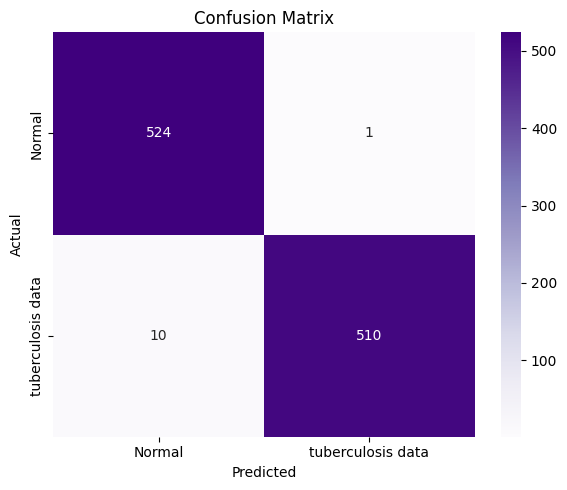

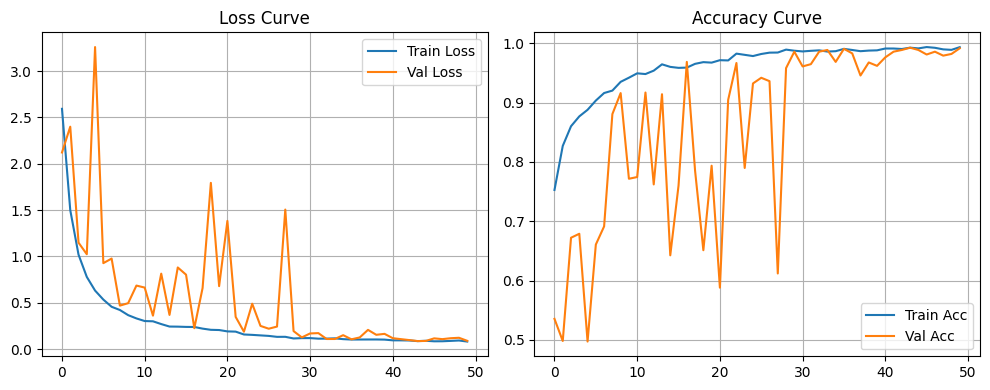

Saved: evaluation_results.txt


In [ ]:
# ============================================================
# 8. EVALUASI MODEL PADA TEST SET
# ============================================================

from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# evaluasi basic
test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
print(f"\nTest Accuracy: {test_acc:.4f} | Loss: {test_loss:.4f}")

# prediksi test set
preds = best_model.predict(test_ds, verbose=0)
y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])
y_pred = np.argmax(preds, axis=1)

# metrik tambahan
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print(f"Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# confusion matrix (INI CONFUSION MATRIX BIASA, BUKAN NORMALIZED)
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap='Purples',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# plot kurva training final
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("Loss Curve"); plt.legend(); plt.grid(True)

plt.subplot(1,2,2)
plt.plot(history.history["accuracy"], label="Train Acc")
plt.plot(history.history["val_accuracy"], label="Val Acc")
plt.title("Accuracy Curve"); plt.legend(); plt.grid(True)

plt.tight_layout()
plt.show()

# simpan hasil evaluasi ke file
with open("evaluation_results.txt", "w") as f:
    f.write(f"Test Accuracy: {test_acc:.4f} | Loss: {test_loss:.4f}\n")
    f.write(f"Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}\n\n")
    f.write(classification_report(y_true, y_pred, target_names=class_names, digits=4))

print("Saved: evaluation_results.txt")


Saving tuberculosis_036_jpg.rf.317a12148243e92899ce1ae156f4445c.jpg to tuberculosis_036_jpg.rf.317a12148243e92899ce1ae156f4445c.jpg

📸 Gambar: tuberculosis_036_jpg.rf.317a12148243e92899ce1ae156f4445c.jpg


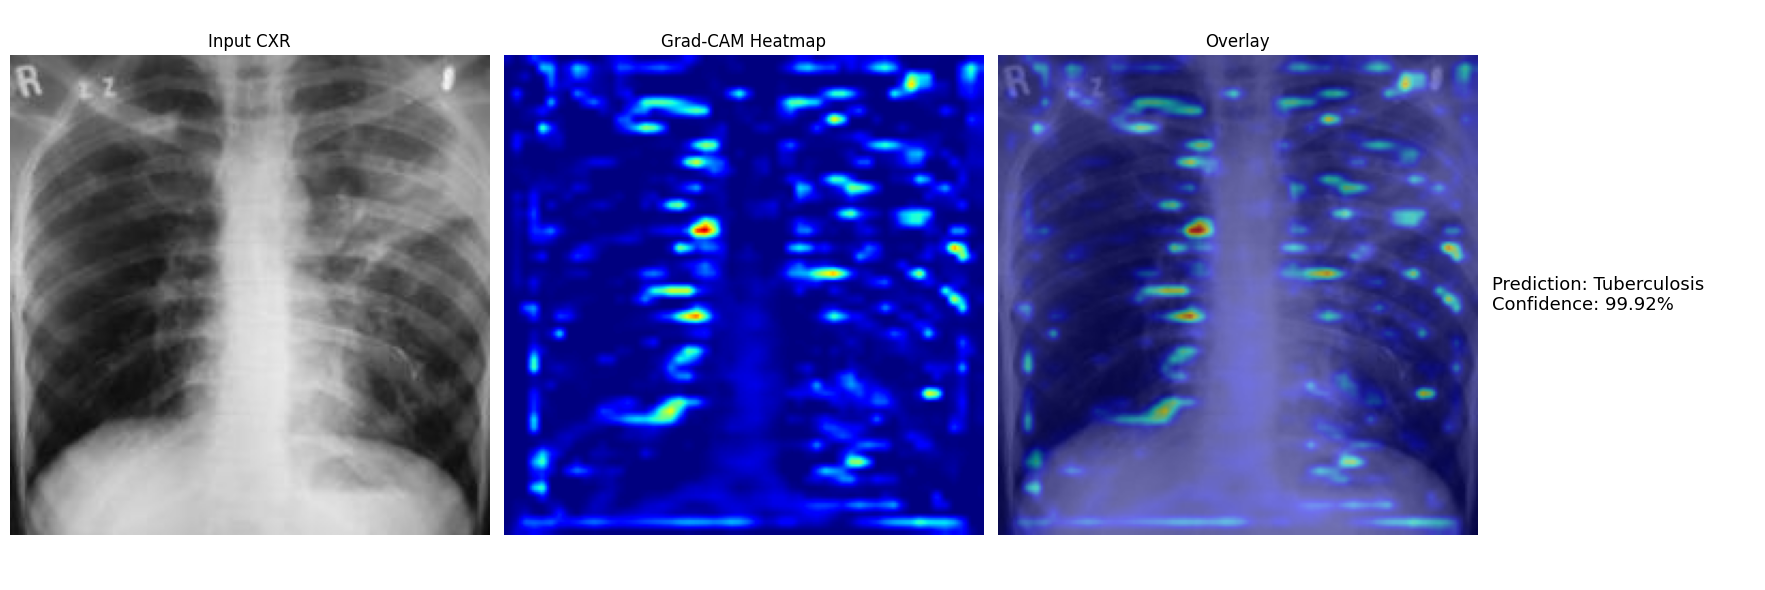

In [ ]:
# ============================================================
# 9. GRAD-CAM
# ============================================================
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from google.colab import files

MODEL_PATH   = "cnn_tb_best.h5"
CLASS_NAMES  = ["Normal", "Tuberculosis"]
IMG_SIZE     = (224, 224)
TARGET_LAYER = "conv2d_2"

ALPHA_IMG   = 0.50
ALPHA_HEAT  = 0.50

model = load_model(MODEL_PATH)

def preprocess(path):
    img = tf.keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = tf.keras.utils.img_to_array(img).astype(np.float32) / 255.0
    return arr, np.expand_dims(arr, 0)

def adapt_inputs(m, x):
    for c in (x, [x], [[x]], {"input_layer_1": x}):
        try:
            _ = m(c, training=False)
            return c
        except Exception:
            pass
    return x

def compute_gradcam(img_tensor, class_idx):
    conv_layer = model.get_layer(TARGET_LAYER)
    grad_model = tf.keras.models.Model(model.inputs, [conv_layer.output, model.output])
    inp = adapt_inputs(grad_model, img_tensor)

    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(inp, training=False)
        score = preds[:, class_idx]

    grads = tape.gradient(score, conv_out)

    conv_out = conv_out[0]  # (h,w,c)
    grads = grads[0]        # (h,w,c)

    weights = tf.reduce_mean(grads, axis=(0, 1))          # (c,)
    cam = tf.reduce_sum(conv_out * weights, axis=-1)      # (h,w)
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy()  # masih (h,w) kecil

def make_overlay(img_float01, cam01):
    base = np.uint8(np.clip(img_float01 * 255.0, 0, 255))  # (H,W,3) RGB uint8
    H, W = base.shape[:2]

    # ---- FIX: resize CAM ke ukuran gambar ----
    cam_resized = cv2.resize(cam01, (W, H), interpolation=cv2.INTER_LINEAR)
    cam_u8 = np.uint8(255 * cam_resized)

    heat_bgr = cv2.applyColorMap(cam_u8, cv2.COLORMAP_JET)      # (H,W,3) BGR
    heat_rgb = cv2.cvtColor(heat_bgr, cv2.COLOR_BGR2RGB)        # (H,W,3) RGB

    overlay = cv2.addWeighted(base, ALPHA_IMG, heat_rgb, ALPHA_HEAT, 0)
    return cam_resized, heat_rgb, overlay

# ================= RUN =================
uploaded = files.upload()

for img_path in uploaded.keys():
    print(f"\n📸 Gambar: {img_path}")

    img, x = preprocess(img_path)

    probs = model.predict(adapt_inputs(model, x), verbose=0)[0]
    pred_idx = int(np.argmax(probs))
    pred_class = CLASS_NAMES[pred_idx]
    confidence = float(probs[pred_idx]) * 100

    cam = compute_gradcam(x, pred_idx)
    cam_resized, heat_rgb, overlay = make_overlay(img, cam)

    fig, axs = plt.subplots(1, 4, figsize=(18, 6),
                            gridspec_kw={"width_ratios": [1, 1, 1, 0.55]})

    axs[0].imshow(img)
    axs[0].set_title("Input CXR")
    axs[0].axis("off")

    axs[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
    axs[1].set_title("Grad-CAM Heatmap")
    axs[1].axis("off")

    axs[2].imshow(overlay)
    axs[2].set_title("Overlay")
    axs[2].axis("off")

    axs[3].axis("off")
    axs[3].text(0.0, 0.5,
                f"Prediction: {pred_class}\nConfidence: {confidence:.2f}%",
                fontsize=13, va="center")

    plt.tight_layout()
    plt.show()